# 17 · Multivariable basics

With several inputs and outputs the transfer function becomes a matrix, gain becomes direction-dependent, and
loops interact: moving one input disturbs every output. This notebook introduces the tools that make the
transition: the transfer matrix and its singular values, transmission zeros, the relative gain array that
measures interaction and recommends a pairing, static decoupling, and a decentralised PI design on the Wood-Berry
distillation column with and without a decoupler - where SISO intuition ends and the multivariable design
methods begin.

**What you will learn**
- form the transfer matrix and read direction-dependent gain from singular values
- compute the RGA and choose a pairing
- apply static decoupling
- recognise when decentralised control fails and multivariable design is needed

**Before you start:** notebooks 06 and 10  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, mimo, frequency as fr, response as rs, design as dg, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The transfer matrix and direction-dependent gain

top composition     : reflux: TransferFunction(0.7665 / s + 0.05988) | steam: TransferFunction(-0.9 / s + 0.04762)
bottom composition  : reflux: TransferFunction(0.6055 / s + 0.09174) | steam: TransferFunction(-1.347 / s + 0.06944)


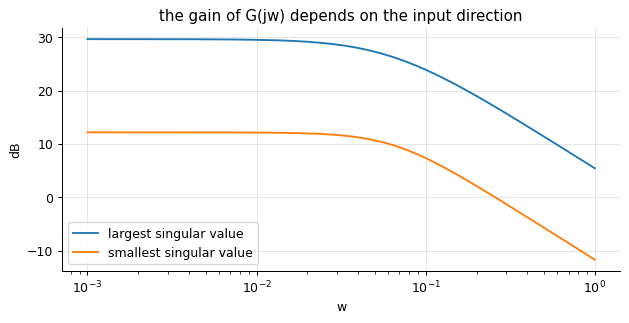

at dc the gains range from 4.06 to 30.40: condition number 7.5


In [2]:
col = models.distillation_2x2()
G = col["system"]
TM = mimo.transfer_matrix(G)
for i in range(2):
    print(f"{col['outputs'][i]:<20}:", " | ".join(f"{col['inputs'][j]}: {TM[i][j]}" for j in range(2)))
w = np.logspace(-3, 0, 300)
sv = mimo.sigma(G, w)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogx(w, 20 * np.log10(sv[:, 0]), label="largest singular value"); ax.semilogx(w, 20 * np.log10(sv[:, 1]), label="smallest singular value"); ax.legend(); ax.set_xlabel("w"); ax.set_ylabel("dB"); ax.set_title("the gain of G(jw) depends on the input direction"); plt.show()
print(f"at dc the gains range from {sv[0, 1]:.2f} to {sv[0, 0]:.2f}: condition number {mimo.condition_number(G, 0.0)[0]:.1f}")

Each entry of the transfer matrix is a SISO transfer function (reflux to top composition, steam to bottom
composition, and the two cross couplings), but the system's gain at a frequency is not a number: it lies
between the smallest and largest singular values of G(jω), depending on the direction of the input vector. A
condition number of 7.5 at dc means some input combinations move the outputs seven times more than others -
the column is moderately ill-conditioned, a fact that no single-loop analysis reveals.

## Interaction: the relative gain array

In [3]:
G0 = G.dcgain()
print("dc gain matrix:\n", np.round(G0, 2))
pair = mimo.rga_pairing(G0)
print("RGA:\n", np.round(pair["rga"], 3), "\nrecommended pairing (output, input):", pair["pairs"], "| any negative relative gains:", pair["negative_entries"])
D = mimo.static_decoupler(G0)
print("static decoupler D = G(0)^-1:\n", np.round(D, 4), "\nG(0) D =\n", np.round(G0 @ D, 10))
print("transmission zeros of the column (none in the right half-plane):", np.round(mimo.transmission_zeros(G), 4))

dc gain matrix:
 [[ 12.8 -18.9]
 [  6.6 -19.4]]
RGA:
 [[ 2.009 -1.009]
 [-1.009  2.009]] 
recommended pairing (output, input): [(0, 0), (1, 1)] | any negative relative gains: True
static decoupler D = G(0)^-1:
 [[ 0.157  -0.1529]
 [ 0.0534 -0.1036]] 
G(0) D =
 [[ 1. -0.]
 [-0.  1.]]
transmission zeros of the column (none in the right half-plane): [-0.1079 -0.0427]


The relative gain λ_ij compares the gain from input j to output i with all other loops open and with them
closed; a value of 1 means the other loops do not interfere, 0.5 means they halve it, a negative value means
the sign reverses when the other loops close - a loop that would run away. The Wood-Berry column's diagonal
relative gains of 2.0 say the two loops fight each other (each loop sees half its gain once the other is
closed), and the pairing rule still picks the diagonal. A static decoupler inverts the dc gain so that each
input affects one output at steady state; dynamic interaction remains.

## Decentralised PI control, with and without a decoupler

decentralised PI      : closed-loop poles [-0.178+0.j   -0.069+0.j   -0.068-0.01j -0.068+0.01j] ... ; peak disturbance of the other output 0.267
PI + static decoupler : closed-loop poles [-0.109-0.059j -0.109+0.059j -0.069+0.j    -0.067+0.j   ] ... ; peak disturbance of the other output 0.090


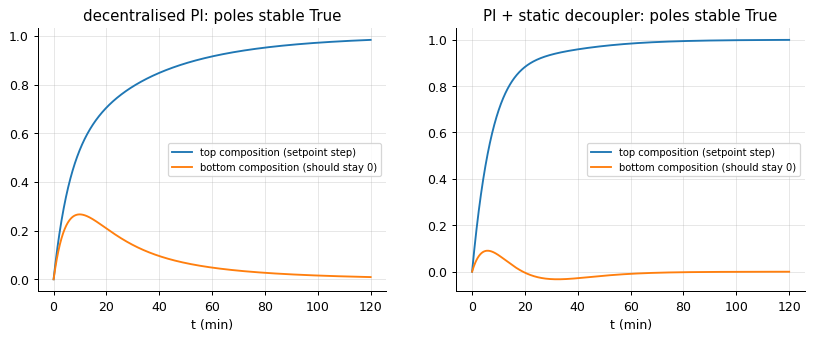

In [4]:
def closed_loop_2x2(plant, controllers, decoupler=None):
    # u = D v, v_i = C_i (r_i - y_i): build the loop in state space
    C1, C2 = controllers
    Cs = sy.ss(np.block([[C1.to_ss().A, np.zeros((1, 1))], [np.zeros((1, 1)), C2.to_ss().A]]), np.block([[C1.to_ss().B, np.zeros((1, 1))], [np.zeros((1, 1)), C2.to_ss().B]]),
               np.block([[C1.to_ss().C, np.zeros((1, 1))], [np.zeros((1, 1)), C2.to_ss().C]]), np.block([[C1.to_ss().D, np.zeros((1, 1))], [np.zeros((1, 1)), C2.to_ss().D]]))
    if decoupler is not None:
        Cs = sy.ss(Cs.A, Cs.B, decoupler @ Cs.C, decoupler @ Cs.D)
    return sy.feedback(sy.series(Cs, plant))
# PI loops tuned by SIMC (lambda = 10 min) on the diagonal elements; with the decoupler the controllers see G D, whose
# dc gains are +1 on both channels, so they are retuned for unit gain (the raw steam loop's negative gain would become positive feedback)
C1 = dg.pid_standard(16.7 / (12.8 * 10.0), min(16.7, 40.0))                 # top composition from reflux
C2 = dg.pid_standard(-14.4 / (19.4 * 10.0), min(14.4, 40.0))                # bottom composition from steam (negative gain)
C1d = dg.pid_standard(16.7 / 10.0, min(16.7, 40.0))                          # the same rule on the decoupled channels
C2d = dg.pid_standard(14.4 / 10.0, min(14.4, 40.0))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, ctrls, dec) in zip(axes, (("decentralised PI", (C1, C2), None), ("PI + static decoupler", (C1d, C2d), D))):
    T = closed_loop_2x2(G, ctrls, dec)
    t, y = rs.step(T, 120.0, input_index=0)
    ax.plot(t, y[:, 0], label="top composition (setpoint step)"); ax.plot(t, y[:, 1], label="bottom composition (should stay 0)")
    ax.set_title(f"{name}: poles stable {np.max(T.poles().real) < 0}"); ax.legend(fontsize=8); ax.set_xlabel("t (min)")
    print(f"{name:<22}: closed-loop poles {np.round(np.sort_complex(T.poles())[:4], 3)} ... ; peak disturbance of the other output {np.max(np.abs(y[:, 1])):.3f}")
plt.show()

Two PI loops tuned on the diagonal elements as if they were alone are stable together here, but a setpoint
step on the top composition disturbs the bottom one by a quarter of the step - the interaction the RGA warned
of. The static decoupler removes the steady-state coupling and cuts the cross-disturbance to a third, with
faster loops - once the controllers are retuned for the plant they now see, G·D with unit positive gains (the
steam loop's original negative gain would otherwise become positive feedback and a slowly unstable loop, a
trap this notebook's first draft fell into). What remains is dynamic interaction (the cross terms have
different time constants), which only a dynamic decoupler or a full multivariable design (LQG, H∞) removes. The lesson of the chapter: MIMO plants need MIMO
analysis before any loop is closed, and the RGA is the first thing to compute.

## Inside the algorithm: the RGA element by element

In [5]:
lam11_open = G0[0, 0]                                  # gain reflux -> top with the other loop open
Ginv = np.linalg.inv(G0)
lam11_closed = 1 / Ginv[0, 0]                           # gain with the other loop perfectly closed
print(f"open-loop gain {lam11_open:.2f}, closed-loop gain {lam11_closed:.2f}, ratio = relative gain {lam11_open / lam11_closed:.3f}; RGA[0,0] = {mimo.rga(G0)[0, 0]:.3f}")

open-loop gain 12.80, closed-loop gain 6.37, ratio = relative gain 2.009; RGA[0,0] = 2.009


## Exercises
1. Design the two PI loops of the column by SIMC with lambda = 5, 10 and 20 min, with and without the static decoupler, and tabulate the interaction (peak of the other output for a setpoint step) and the settling time. Does decoupling ever hurt?
2. For the quarter car (inputs: road and actuator force; outputs: body acceleration and suspension travel) compute the singular values from 0.1 to 100 rad/s and explain the two peaks. Which input direction is the hardest to attenuate?
3. **Implement it yourself:** write a dynamic decoupler D(s) = G(s)^-1 G_diag(s) for the 2 x 2 column (each entry a transfer function) and show that G D is diagonal; is D proper and stable?